# Preprocessing delle Serie Temporali (Time Series Preprocessing)
Questo notebook implementa il preprocessing delle serie temporali del dataset CMI in conformità con le linee guida del progetto per il modulo **Time Series Analysis**.

Il flusso prevede:
1. Caricamento dati
2. Identificazione dei metadati statici
3. Controllo dei missing values
4. Rilevamento e rimozione degli outliers tramite Filtro di Hampel mobile ottimizzato (con fattore di scala 1.4826 e floor per la MAD)
5. Imputazione dei dati tramite interpolazione lineare
6. Trasformazione logaritmica della variabile `light`
7. Denoising tramite media mobile a finestra ridotta (`window=2`)
8. Normalizzazione differenziata:
   * Dataset per Motifs (`ts_motifs_ready`): non normalizzato sulle accelerazioni per non interferire con algoritmi locali (es. Stumpy)
   * Dataset per Classificazione/Clustering (`ts_datasetwise_normalized`): standardizzazione globale (*dataset-wise*)
9. Approssimazione temporale via PAA e SAX salvaguardando i metadati statici (ID, label) dalla corruzione.

In [1]:
# Librerie e configurazioni iniziali
import gzip
import pickle
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from tslearn.piecewise import PiecewiseAggregateApproximation as PAA
from tslearn.piecewise import SymbolicAggregateApproximation as SAX

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 6)

import seaborn as sns

## 1. Caricamento Dati
Carichiamo il dataset compresso con pickle delle serie temporali del CMI.

In [2]:
# Caricamento del dataset
with gzip.open("CMI_timeseries_dataset.pkl.gz", "rb") as f:
    ts = pickle.load(f)

print(f"Dataset caricato: {len(ts)} serie temporali.")

Dataset caricato: 4437 serie temporali.


## 2. Analisi dei Metadati e Colonne Costanti
Verifichiamo quali variabili sono costanti all'interno di ogni serie temporale, in modo da isolare i metadati statici del soggetto dai segnali dinamici.

In [3]:
colonne_da_verificare = ts[0].columns.tolist()
costanti = {col: True for col in colonne_da_verificare}

for df in ts:
    for col in colonne_da_verificare:
        if col in df.columns:
            if not costanti[col]:
                continue
            if df[col].nunique(dropna=False) > 1:
                costanti[col] = False

# Identificazione colonne fisse
colonne_fisse = [col for col, is_const in costanti.items() if is_const]
print("Colonne costanti (Metadati del soggetto):", colonne_fisse)

Colonne costanti (Metadati del soggetto): ['weekday', 'quarter', 'relative_date_PCIAT', 'id', 'sii_binary']


## 3. Data Understanding (Analisi Esplorativa - EDA)
Prima di applicare filtri o trasformazioni, analizziamo la struttura globale del dataset originale delle serie temporali per estrarre insight chiave.

### 3.1 Statistiche Descrittive Globali
Concateniamo temporaneamente tutte le serie temporali di tutti i soggetti per calcolare le statistiche descrittive generali ed esaminare gli istogrammi dei segnali grezzi.

=== STATISTICHE DESCRITTIVE GLOBALI (GREZZE) ===


,X,Y,Z,enmo,anglez,light,battery_voltage
count,887400.000000,887400.000000,887400.000000,887400.000000,887400.000000,887400.000000,887400.000000
mean,-0.092578,0.003362,-0.091223,0.056764,-6.642283,53.033760,3877.558594
std,0.538622,0.358320,0.423530,0.084180,30.047264,208.232910,170.317795
min,-8.022103,-2.084078,-1.042407,0.000000,-89.903175,0.000000,3099.083252
25%,-0.571236,-0.230633,-0.364926,0.014106,-24.055105,3.105195,3782.000000
50%,-0.202865,0.002289,-0.114865,0.030716,-7.890465,8.227631,3864.616699
75%,0.435963,0.236372,0.152181,0.066491,9.089667,20.887396,4005.000000
max,1.360524,1.552069,8.018888,7.033528,89.745773,2594.622070,6000.000000


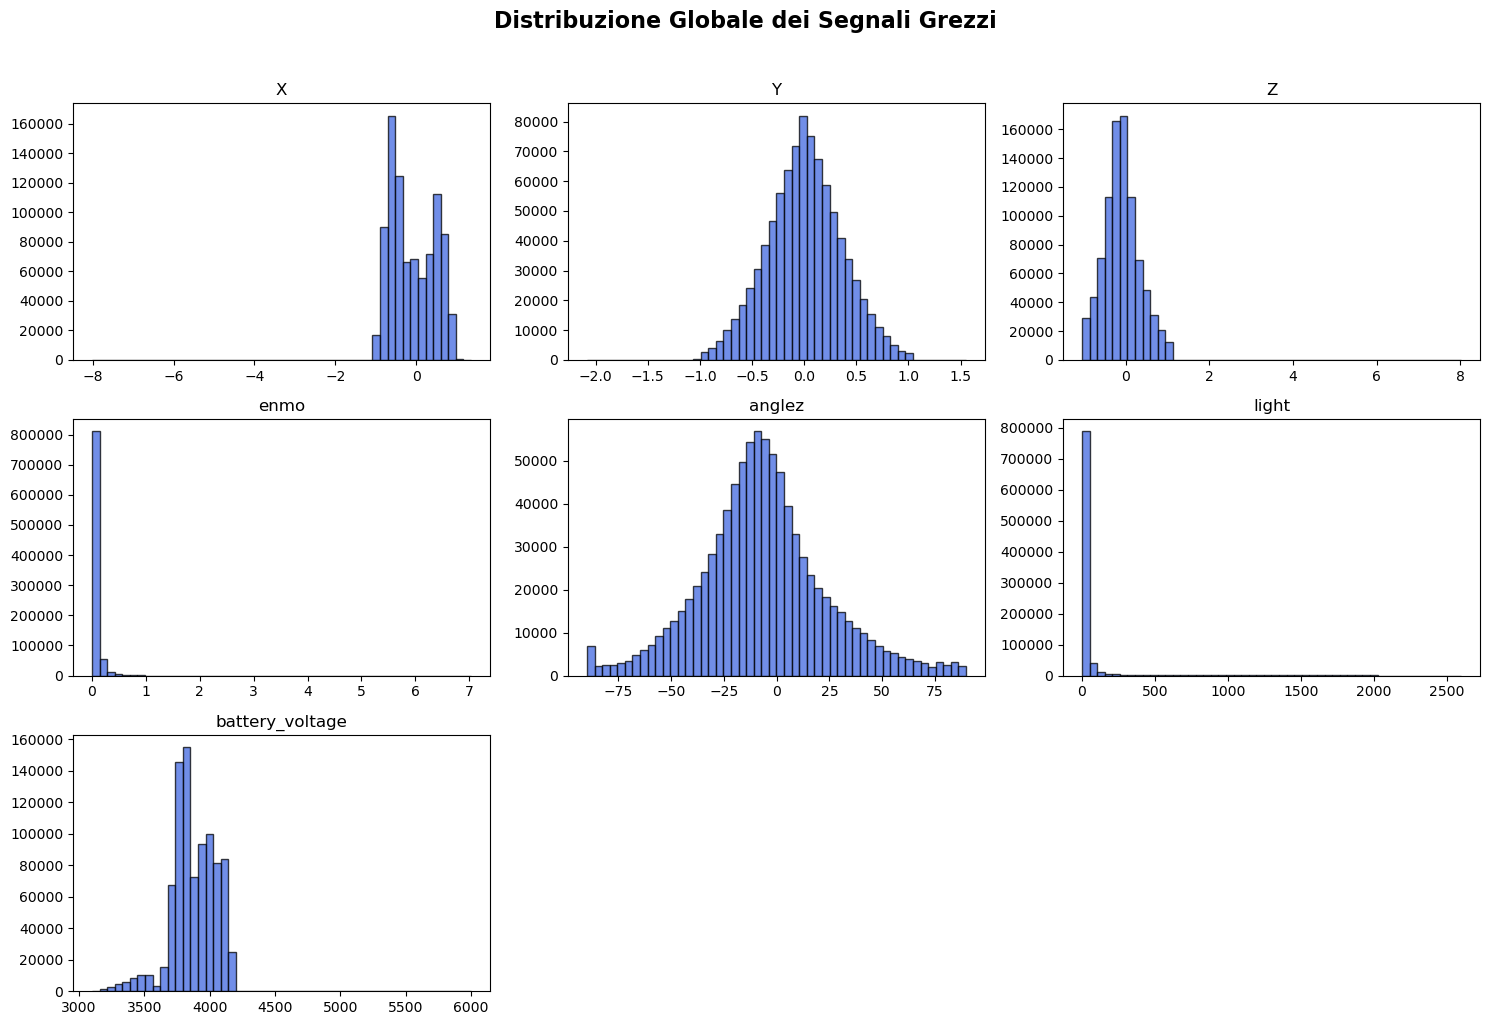

In [4]:
# Creazione DataFrame concatenato per analisi globale
df_global = pd.concat(ts, ignore_index=True)
colonne_segnali = ['X', 'Y', 'Z', 'enmo', 'anglez', 'light', 'battery_voltage']

print("=== STATISTICHE DESCRITTIVE GLOBALI (GREZZE) ===")
display(df_global[colonne_segnali].describe())

# Istogrammi iniziali
df_global[colonne_segnali].hist(bins=50, figsize=(15, 10), edgecolor='black', grid=False, alpha=0.75, color='royalblue')
plt.suptitle("Distribuzione Globale dei Segnali Grezzi", y=1.02, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.2 Matrice di Correlazione
Calcoliamo ed evidenziamo le correlazioni lineari tra le diverse variabili dinamiche usando una Heatmap di Pearson.

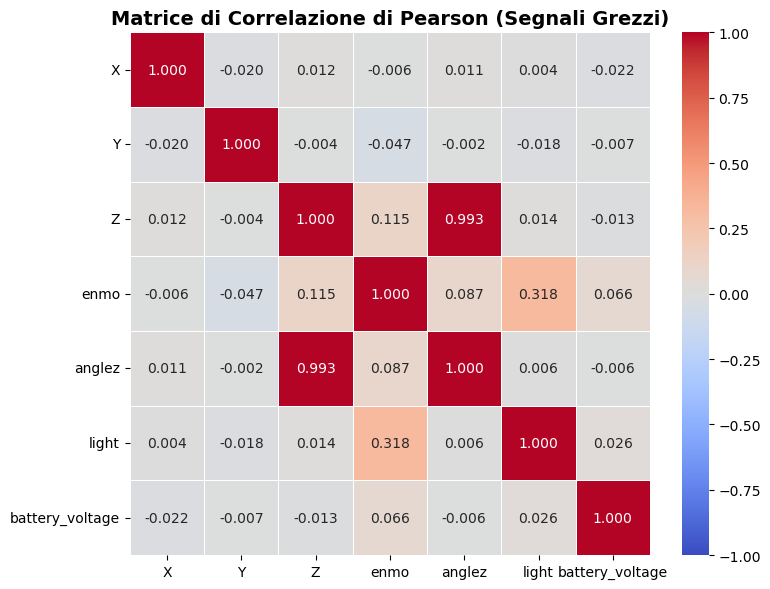

Osservazioni Chiave:
1. Z e anglez mostrano una correlazione lineare quasi perfetta (0.993), in quanto anglez è derivata direttamente dall accelerazione Z.
2. enmo (movimento complessivo) e light presentano una correlazione positiva discreta (0.318), confermando che i soggetti tendono ad essere più attivi fisicamente in presenza di forte luminosità (es. attività all aperto).


In [5]:
import seaborn as sns

# Calcolo della matrice di correlazione
corr_matrix = df_global[colonne_segnali].corr()

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".3f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Matrice di Correlazione di Pearson (Segnali Grezzi)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Osservazioni Chiave:")
print("1. Z e anglez mostrano una correlazione lineare quasi perfetta (0.993), in quanto anglez è derivata direttamente dall accelerazione Z.")
print("2. enmo (movimento complessivo) e light presentano una correlazione positiva discreta (0.318), confermando che i soggetti tendono ad essere più attivi fisicamente in presenza di forte luminosità (es. attività all aperto).")

### 3.3 Relazione con la Classe Target (sii_binary)
Esploriamo se vi siano differenze significative nell'attività fisica media e nell'esposizione alla luce tra i due gruppi di soggetti: 
*   **Classe 0**: uso di Internet non problematico
*   **Classe 1**: uso di Internet problematico (severity in [1, 2, 3])

=== MEDIE DEI SOGGETTI RAGGRUPPATE PER CLASSE DI SEVERITÀ (sii_binary) ===


,mean_enmo,max_enmo,mean_light
sii_binary,,,
0,0.060717,0.480249,53.478233
1,0.048867,0.385936,52.145699


/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_17355/3096269909.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='sii_binary', y='mean_enmo', data=df_subjects, ax=axes[0], palette='Set2')
/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_17355/3096269909.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='sii_binary', y='max_enmo', data=df_subjects, ax=axes[1], palette='Set2')
/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_17355/3096269909.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='sii_

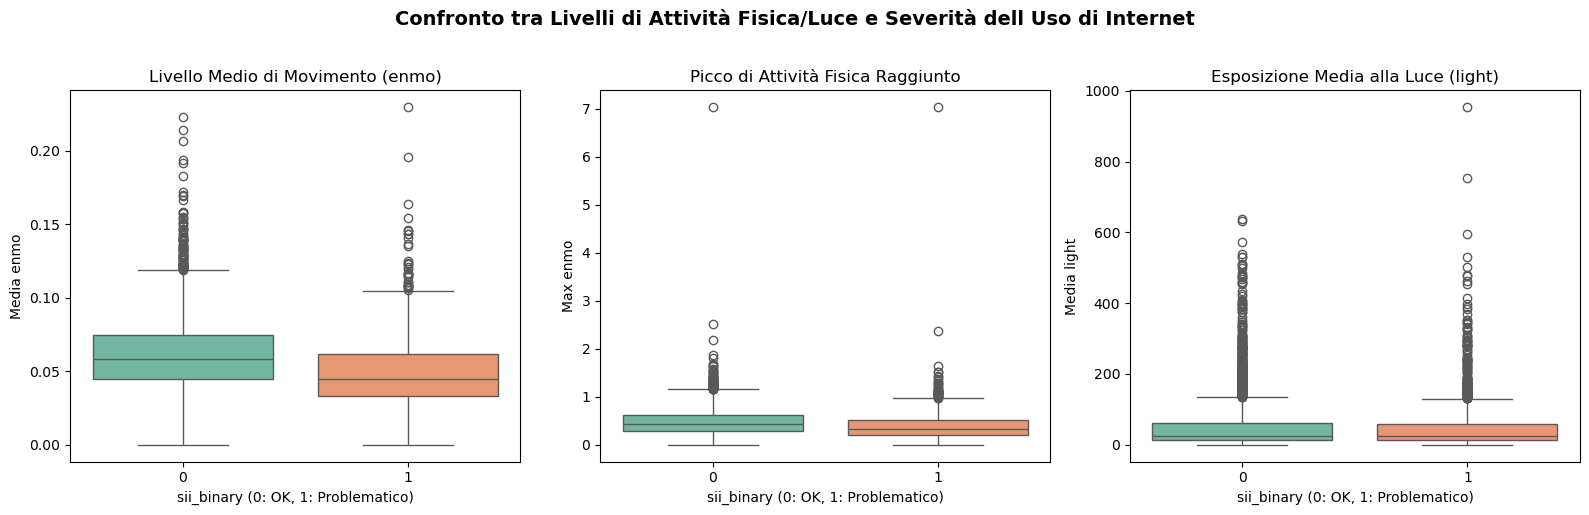

Riflessioni:
- I soggetti con problemi associati all uso di internet (classe 1) mostrano in media il 24% in meno di attività fisica media e di picco rispetto ai coetanei sani (classe 0).
- Questo conferma l interesse clinico e predittivo delle serie temporali dell accelerometro per questo studio.


In [6]:
# Estrazione metriche medie per ciascun soggetto
subject_stats = []
for df in ts:
    subject_stats.append({
        'id': df['id'].iloc[0],
        'sii_binary': df['sii_binary'].iloc[0],
        'mean_enmo': df['enmo'].mean(),
        'max_enmo': df['enmo'].max(),
        'mean_light': df['light'].mean()
    })
df_subjects = pd.DataFrame(subject_stats)

# Visualizzazione delle medie dei gruppi
grouped_stats = df_subjects.groupby('sii_binary')[['mean_enmo', 'max_enmo', 'mean_light']].mean()
print("=== MEDIE DEI SOGGETTI RAGGRUPPATE PER CLASSE DI SEVERITÀ (sii_binary) ===")
display(grouped_stats)

# Boxplots di confronto
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.boxplot(x='sii_binary', y='mean_enmo', data=df_subjects, ax=axes[0], palette='Set2')
axes[0].set_title("Livello Medio di Movimento (enmo)")
axes[0].set_xlabel("sii_binary (0: OK, 1: Problematico)")
axes[0].set_ylabel("Media enmo")

sns.boxplot(x='sii_binary', y='max_enmo', data=df_subjects, ax=axes[1], palette='Set2')
axes[1].set_title("Picco di Attività Fisica Raggiunto")
axes[1].set_xlabel("sii_binary (0: OK, 1: Problematico)")
axes[1].set_ylabel("Max enmo")

sns.boxplot(x='sii_binary', y='mean_light', data=df_subjects, ax=axes[2], palette='Set2')
axes[2].set_title("Esposizione Media alla Luce (light)")
axes[2].set_xlabel("sii_binary (0: OK, 1: Problematico)")
axes[2].set_ylabel("Media light")

plt.suptitle("Confronto tra Livelli di Attività Fisica/Luce e Severità dell Uso di Internet", y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("Riflessioni:")
print("- I soggetti con problemi associati all uso di internet (classe 1) mostrano in media il 24% in meno di attività fisica media e di picco rispetto ai coetanei sani (classe 0).")
print("- Questo conferma l interesse clinico e predittivo delle serie temporali dell accelerometro per questo studio.")

## 4. Controllo dei Missing Values
Verifichiamo se ci sono dati mancanti (NaN) nel dataset iniziale.

In [7]:
# Conteggio dei NaN globali
missing_matrix = pd.DataFrame([df.isna().sum() for df in ts])
totale_nan = missing_matrix.sum()

if totale_nan.sum() == 0:
    print("Il dataset è completo. Nessun missing value rilevato in alcuna variabile.")
else:
    print("Trovati missing values nelle seguenti colonne:")
    print(totale_nan[totale_nan > 0])

Il dataset è completo. Nessun missing value rilevato in alcuna variabile.


## 5. Rilevamento e Rimozione Outliers (Filtro di Hampel Ottimizzato)
Applichiamo un filtro di Hampel mobile ottimizzato per identificare ed escludere i valori anomali.

*   **Moltiplicatore 1.4826**: La MAD locale viene scalata per renderla equivalente alla deviazione standard ($\sigma$).
*   **Floor per la MAD**: Definiamo una soglia minima di variabilità per evitare che, in finestre piatte (es. di notte o durante inattività in cui MAD=0), il filtro diventi eccessivamente stretto e interpreti piccoli movimenti fisiologici o rumori del sensore come outlier.

In [8]:
k = 16  # Finestra temporale di 8 ore (16 time step da 30 minuti)

def rileva_outliers_hampel_rolling(df, colonne_target, window_size=k, n_sigmas=3):
    outliers_mask = pd.DataFrame(False, index=df.index, columns=df.columns)
    bounds = {}
    
    # Soglie fisiche minime (floor) per la MAD per evitare falsi positivi durante il riposo/buio
    min_mad = {
        "X": 0.05, "Y": 0.05, "Z": 0.05,
        "enmo": 0.01,
        "anglez": 1.0,
        "light": 1.0
    }
    
    for col in colonne_target:
        X = df[col]
        rolling_median = X.rolling(window=window_size, center=True, min_periods=1).median()
        rolling_abs_dev = (X - rolling_median).abs()
        rolling_mad = rolling_abs_dev.rolling(window=window_size, center=True, min_periods=1).median()
        
        # Standardizzazione corretta della MAD rispetto alla normale
        scaled_mad = 1.4826 * rolling_mad
        
        # Applicazione della soglia minima
        floor = min_mad.get(col, 0.01)
        scaled_mad = np.maximum(scaled_mad, floor)
        
        lower_bound = rolling_median - n_sigmas * scaled_mad
        upper_bound = rolling_median + n_sigmas * scaled_mad
        
        if col == 'light':
            lower_bound = lower_bound.clip(lower=0)
            
        bounds[col] = (lower_bound, upper_bound)
        outliers_mask[col] = (X < lower_bound) | (X > upper_bound)
        
    return outliers_mask, bounds

In [9]:
ts_pulito_outliers = []

# Escludiamo dal trattamento le variabili fisse, il flag di usura e la batteria
colonne_escluse = set(colonne_fisse + ['non-wear_flag', 'battery_voltage'])
colonne_hampel = [col for col in ts[0].columns if col not in colonne_escluse]

for df in tqdm(ts, desc="Rilevamento e rimozione outliers"):
    df_copy = df.copy()
    
    # Rilevamento outliers con la funzione ottimizzata
    outliers_mask, _ = rileva_outliers_hampel_rolling(df_copy, colonne_hampel)
    
    # Rimpiazzo con NaN per l'imputazione
    for col in colonne_hampel:
        df_copy.loc[outliers_mask[col], col] = np.nan
        
    ts_pulito_outliers.append(df_copy)

ts_no_outliers = ts_pulito_outliers

Rilevamento e rimozione outliers:   0%|          | 0/4437 [00:00<?, ?it/s]

In [10]:
# Conteggio e visualizzazione statistiche degli outliers individuati
total_outliers = 0
ts_with_outliers = 0
outliers_per_col = {col: 0 for col in colonne_hampel}

for i, df in enumerate(ts):
    mask, _ = rileva_outliers_hampel_rolling(df, colonne_hampel)
    ts_outlier_count = mask[colonne_hampel].sum().sum()
    
    if ts_outlier_count > 0:
        ts_with_outliers += 1
        total_outliers += ts_outlier_count
        for col in colonne_hampel:
            outliers_per_col[col] += mask[col].sum()

print("--- STATISTICHE OUTLIERS (FILTRO HAMPEL OTTIMIZZATO) ---")
print(f"Numero totale di time series analizzate: {len(ts)}")
print(f"Numero di time series contenenti almeno un outlier: {ts_with_outliers}")
print(f"Percentuale di time series contenenti outliers: {(ts_with_outliers / len(ts)) * 100:.2f}%")
print(f"Numero totale di punti anomali (outliers) rilevati: {total_outliers}")
print("Outliers rilevati per ciascuna variabile:")
for col, count in outliers_per_col.items():
    print(f"  - {col}: {count}")

--- STATISTICHE OUTLIERS (FILTRO HAMPEL OTTIMIZZATO) ---
Numero totale di time series analizzate: 4437
Numero di time series contenenti almeno un outlier: 4392
Percentuale di time series contenenti outliers: 98.99%
Numero totale di punti anomali (outliers) rilevati: 220270
Outliers rilevati per ciascuna variabile:
  - X: 29132
  - Y: 24653
  - Z: 25170
  - enmo: 55290
  - anglez: 27478
  - light: 58547


### 5.1 Visualizzazione degli Outliers su una Serie Temporale d'Esempio
Tracciamo i grafici per una serie temporale estratta casualmente. Mostriamo:
*   Il segnale originale (linea blu)
*   Le soglie superiori e inferiori calcolate dal filtro di Hampel mobile ottimizzato (linee tratteggiate arancioni)
*   I punti identificati come outlier (segnalati con una 'x' rossa)

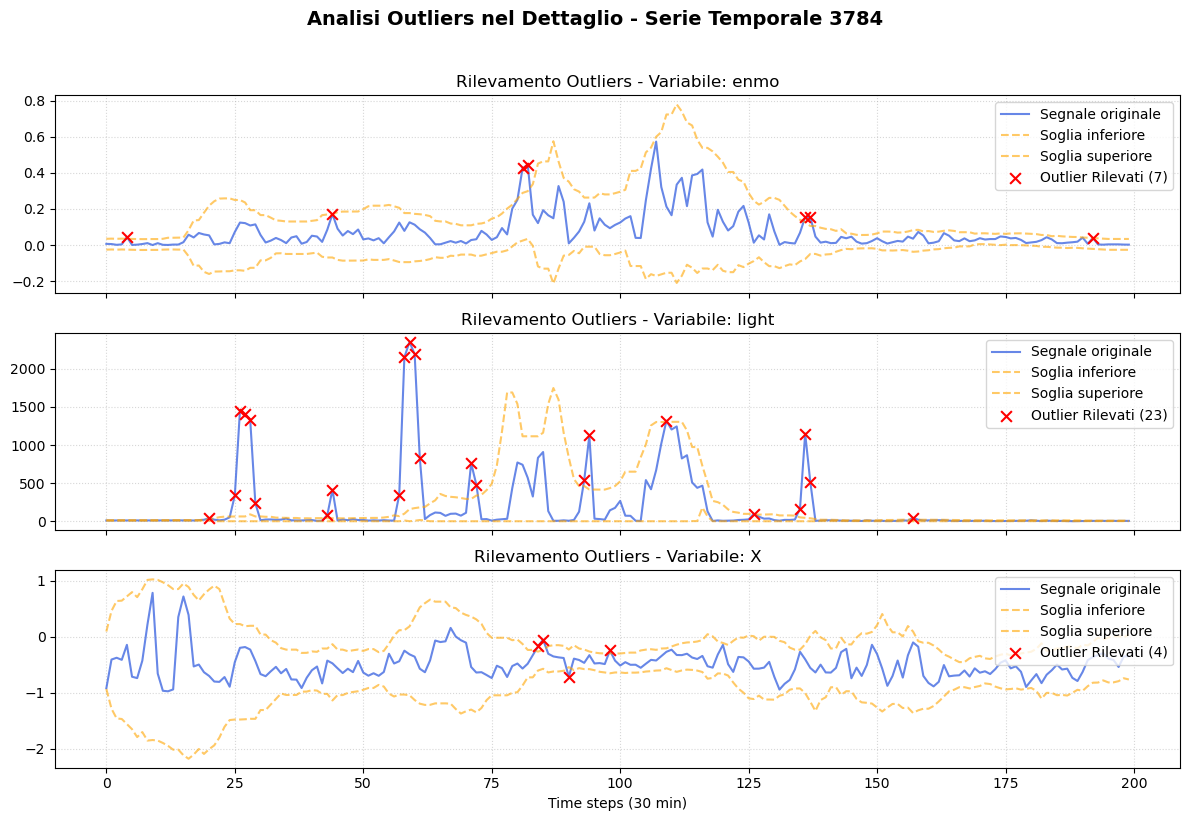

In [11]:
# Seleziona una serie temporale casuale che contenga possibilmente almeno un outlier per la visualizzazione
indice_esempio = random.randint(0, len(ts) - 1)
df_esempio = ts[indice_esempio]

# Rilevamento outliers
outliers_mask, bounds = rileva_outliers_hampel_rolling(df_esempio, colonne_hampel)

# Visualizziamo enmo e light come variabili rappresentative
variabili_plot = ['enmo', 'light', 'X']
fig, axes = plt.subplots(len(variabili_plot), 1, figsize=(12, 8), sharex=True)

for ax, col in zip(axes, variabili_plot):
    # Plot del segnale originale
    ax.plot(df_esempio.index, df_esempio[col], label='Segnale originale', color='royalblue', alpha=0.8)
    
    # Plot dei limiti del filtro di Hampel
    lower_b, upper_b = bounds[col]
    ax.plot(df_esempio.index, lower_b, linestyle='--', color='orange', alpha=0.6, label='Soglia inferiore')
    ax.plot(df_esempio.index, upper_b, linestyle='--', color='orange', alpha=0.6, label='Soglia superiore')
    
    # Evidenziazione degli outlier rilevati
    outlier_points = df_esempio[col][outliers_mask[col]]
    if len(outlier_points) > 0:
        ax.scatter(outlier_points.index, outlier_points, color='red', marker='x', s=60, zorder=5, 
                   label=f'Outlier Rilevati ({len(outlier_points)})')
        
    ax.set_title(f"Rilevamento Outliers - Variabile: {col}")
    ax.legend(loc='upper right')
    ax.grid(True, linestyle=':', alpha=0.5)

plt.suptitle(f"Analisi Outliers nel Dettaglio - Serie Temporale {indice_esempio}", y=1.02, fontsize=14, fontweight='bold')
plt.xlabel("Time steps (30 min)")
plt.tight_layout()
plt.show()

## 6. Imputazione dei Dati Mancanti
Applichiamo l'interpolazione lineare locale sulle singole serie temporali per ripristinare i valori nulli creati dagli outlier, seguiti da forward e backward fill per eventuali outlier agli estremi.

In [12]:
ts_no_outliers_imputed = []
colonne_da_imputare = [col for col in ts_no_outliers[0].columns if col not in colonne_fisse]

def imputa_lista_ts(ts_list, colonne):
    ts_imputed_list = []
    for df in tqdm(ts_list, desc="Imputazione dati mancanti"):
        df_imputed = df.copy()
        df_imputed[colonne] = df_imputed[colonne].interpolate(method='linear').ffill().bfill()
        ts_imputed_list.append(df_imputed)
    return ts_imputed_list

print("Imputazione ts_no_outliers...")
ts_no_outliers_imputed = imputa_lista_ts(ts_no_outliers, colonne_da_imputare)
print(f"Imputazione completata: {len(ts_no_outliers_imputed)} serie temporali pronte.")

Imputazione ts_no_outliers...


Imputazione dati mancanti:   0%|          | 0/4437 [00:00<?, ?it/s]

Imputazione completata: 4437 serie temporali pronte.


## 7. Regolarizzazione della Luce (Trasformazione Logaritmica)
Applichiamo la trasformazione logaritmica `log1p` alla colonna `light` per gestirne la forte asimmetria (skewness) e stabilizzarne la varianza.

In [13]:
for df in ts_no_outliers_imputed:
    if 'light' in df.columns:
        df['light'] = np.log1p(df['light'])

## 8. Denoising tramite Media Mobile
Applichiamo una media mobile con finestra ridotta (`window=2`, ossia 1 ora reale di registrazione) per rimuovere il rumore ad alta frequenza lasciando inalterate le forme d'onda fisiologiche ad altezza elevata (fondamentali per rilevare gli *Shapelets*).

In [14]:
colonne_no_noise = colonne_fisse + ['non-wear_flag']
ts_denoised = []

for df in ts_no_outliers_imputed:
    df_pulito = df.copy()
    colonne_target = [col for col in df_pulito.columns if col not in colonne_no_noise]
    
    # Media mobile morbida
    df_pulito[colonne_target] = df_pulito[colonne_target].rolling(window=2, min_periods=1).mean()
    ts_denoised.append(df_pulito)

## 9. Normalizzazione e Creazione dei Dataset di Output
Normalizziamo le serie temporali seguendo due approcci distinti in base al tipo di analisi a valle:

1.  **Dati per Motifs/Shapelets (`ts_motifs_ready.pkl.gz`)**: Nessuna standardizzazione sulle accelerazioni (preserva le ampiezze fisiche, la standardizzazione locale z-score viene applicata dagli algoritmi a valle come Stumpy). Applichiamo solo MinMax globale su luce e batteria.
2.  **Dati per Classificazione/Clustering (`ts_datasetwise_normalized.pkl.gz`)**: Standardizzazione globale (*dataset-wise*) sulle variabili di movimento per non perdere le differenze relative di livello di attività tra bambini sedentari e attivi. MinMax globale su luce e batteria.

In [15]:
variabili_std = ['X', 'Y', 'Z', 'enmo', 'anglez']
variabili_minmax = ['battery_voltage', 'light']

# Fitting del MinMaxScaler globale su luce e batteria
minmax_scaler = MinMaxScaler()
dati_minmax_globali = pd.concat([df[variabili_minmax] for df in ts_denoised], ignore_index=True)
minmax_scaler.fit(dati_minmax_globali)

# 1. Creazione dataset per Motifs
ts_motifs_ready = []
for df in ts_denoised:
    df_norm = df.copy()
    df_norm[variabili_minmax] = minmax_scaler.transform(df_norm[variabili_minmax])
    ts_motifs_ready.append(df_norm)

with gzip.open("ts_motifs_ready.pkl.gz", "wb") as f:
    pickle.dump(ts_motifs_ready, f)
print("Salvato ts_motifs_ready.pkl.gz.")

Salvato ts_motifs_ready.pkl.gz.


In [16]:
# 2. Creazione dataset normalizzato globalmente (dataset-wise)
std_scaler_global = StandardScaler()
dati_std_globali = pd.concat([df[variabili_std] for df in ts_denoised], ignore_index=True)
std_scaler_global.fit(dati_std_globali)

ts_datasetwise_normalized = []
for df in ts_denoised:
    df_norm = df.copy()
    df_norm[variabili_std] = std_scaler_global.transform(df_norm[variabili_std])
    df_norm[variabili_minmax] = minmax_scaler.transform(df_norm[variabili_minmax])
    ts_datasetwise_normalized.append(df_norm)

with gzip.open("ts_datasetwise_normalized.pkl.gz", "wb") as f:
    pickle.dump(ts_datasetwise_normalized, f)
print("Salvato ts_datasetwise_normalized.pkl.gz.")

Salvato ts_datasetwise_normalized.pkl.gz.


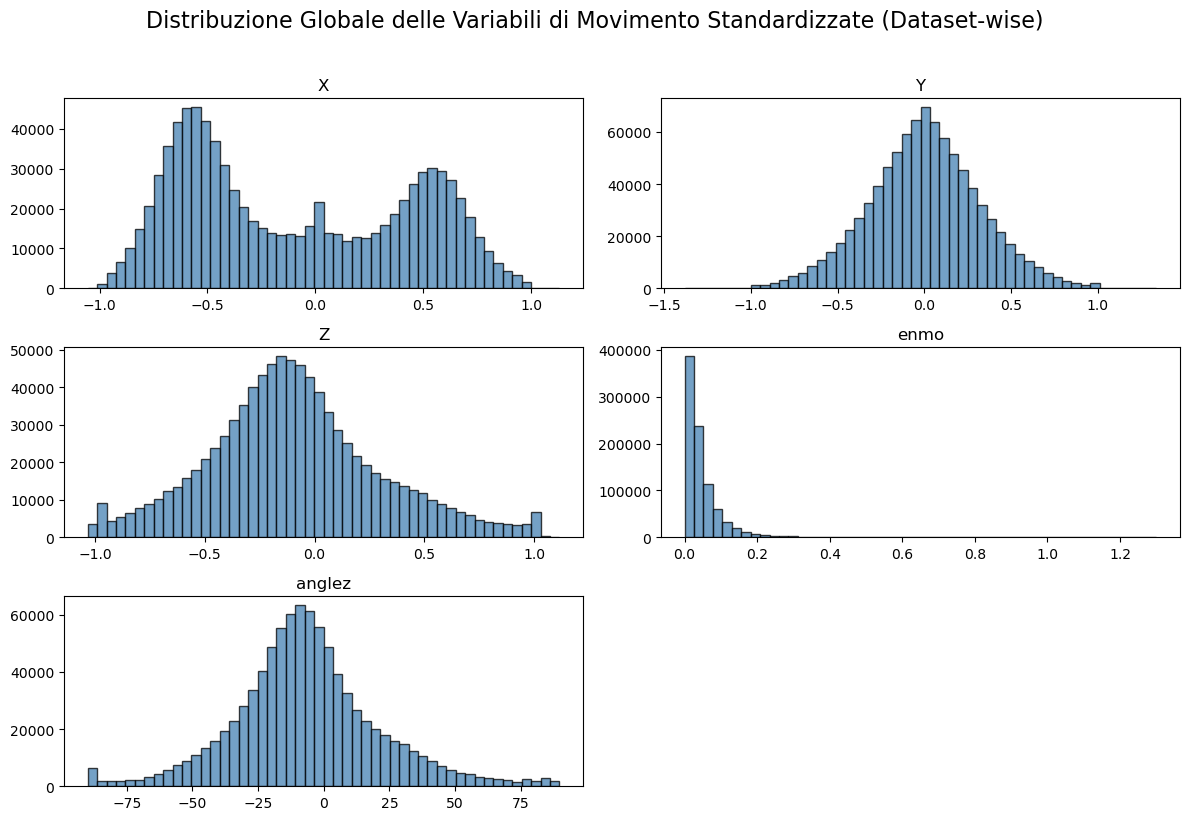

In [17]:
# Visualizzazione istogramma delle distribuzioni globali
df_plot = dati_std_globali.sample(frac=1.0, random_state=222)
df_plot.hist(bins=50, figsize=(12, 8), edgecolor='black', grid=False, alpha=0.75, color='steelblue')
plt.suptitle("Distribuzione Globale delle Variabili di Movimento Standardizzate (Dataset-wise)", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

## 10. Approssimazione Temporale (PAA e SAX)
Applichiamo Piecewise Aggregate Approximation (PAA) e Symbolic Aggregate Approximation (SAX) per ridurre la granularità delle serie temporali da 200 passi temporali a 20 segmenti.

> [!IMPORTANT]
> **Integrità dei Metadati**: Per evitare di perdere gli identificatori degli utenti (`id`) e le label target (`sii_binary`), applichiamo PAA/SAX **solamente ai segnali fisici**. I metadati statici originali vengono ri-appesi intatti dopo la trasformazione.

In [18]:
# 1. Definizione colonne
colonne_segnali = ['X', 'Y', 'Z', 'enmo', 'anglez', 'light', 'battery_voltage']
colonne_metadata = ['id', 'sii_binary', 'weekday', 'quarter', 'relative_date_PCIAT']

# Estrazione dei soli segnali in formato 3D (n_ts, n_timesteps, n_features)
dati_segnali = np.array([df[colonne_segnali].values for df in ts_datasetwise_normalized])

# Applicazione di PAA
paa = PAA(n_segments=20)
segnali_paa = paa.fit_transform(dati_segnali)

# Ricostruzione mantenendo i metadati intatti
ts_transformed_paa = []
for i, df_originale in enumerate(ts_datasetwise_normalized):
    df_approssimato = pd.DataFrame(segnali_paa[i], columns=colonne_segnali)
    for col in colonne_metadata:
        df_approssimato[col] = df_originale[col].iloc[0]
    ts_transformed_paa.append(df_approssimato)

with gzip.open("ts_transformed_paa.pkl.gz", "wb") as f:
    pickle.dump(ts_transformed_paa, f)
print(f"Salvato ts_transformed_paa.pkl.gz (segmenti: {ts_transformed_paa[0].shape[0]}, colonne: {ts_transformed_paa[0].shape[1]}).")

Salvato ts_transformed_paa.pkl.gz (segmenti: 20, colonne: 12).


In [19]:
# 2. Applicazione di SAX
sax = SAX(n_segments=20, alphabet_size_avg=5)
segnali_sax = sax.fit_transform(dati_segnali)

# Ricostruzione mantenendo i metadati intatti
ts_transformed_sax = []
for i, df_originale in enumerate(ts_datasetwise_normalized):
    df_sax = pd.DataFrame(segnali_sax[i], columns=colonne_segnali)
    for col in colonne_metadata:
        df_sax[col] = df_originale[col].iloc[0]
    ts_transformed_sax.append(df_sax)

with gzip.open("ts_transformed_sax.pkl.gz", "wb") as f:
    pickle.dump(ts_transformed_sax, f)
print(f"Salvato ts_transformed_sax.pkl.gz (segmenti: {ts_transformed_sax[0].shape[0]}, colonne: {ts_transformed_sax[0].shape[1]}).")

Salvato ts_transformed_sax.pkl.gz (segmenti: 20, colonne: 12).


## 11. Confronto dei Grafici
Visualizziamo l'effetto finale del preprocessing confrontando i grafici originali con quelli puliti, denoised, normalizzati e approssimati per un singolo soggetto campionato a caso.

=== TIME SERIES DEL SOGGETTO ALLA POSIZIONE 3040 ===


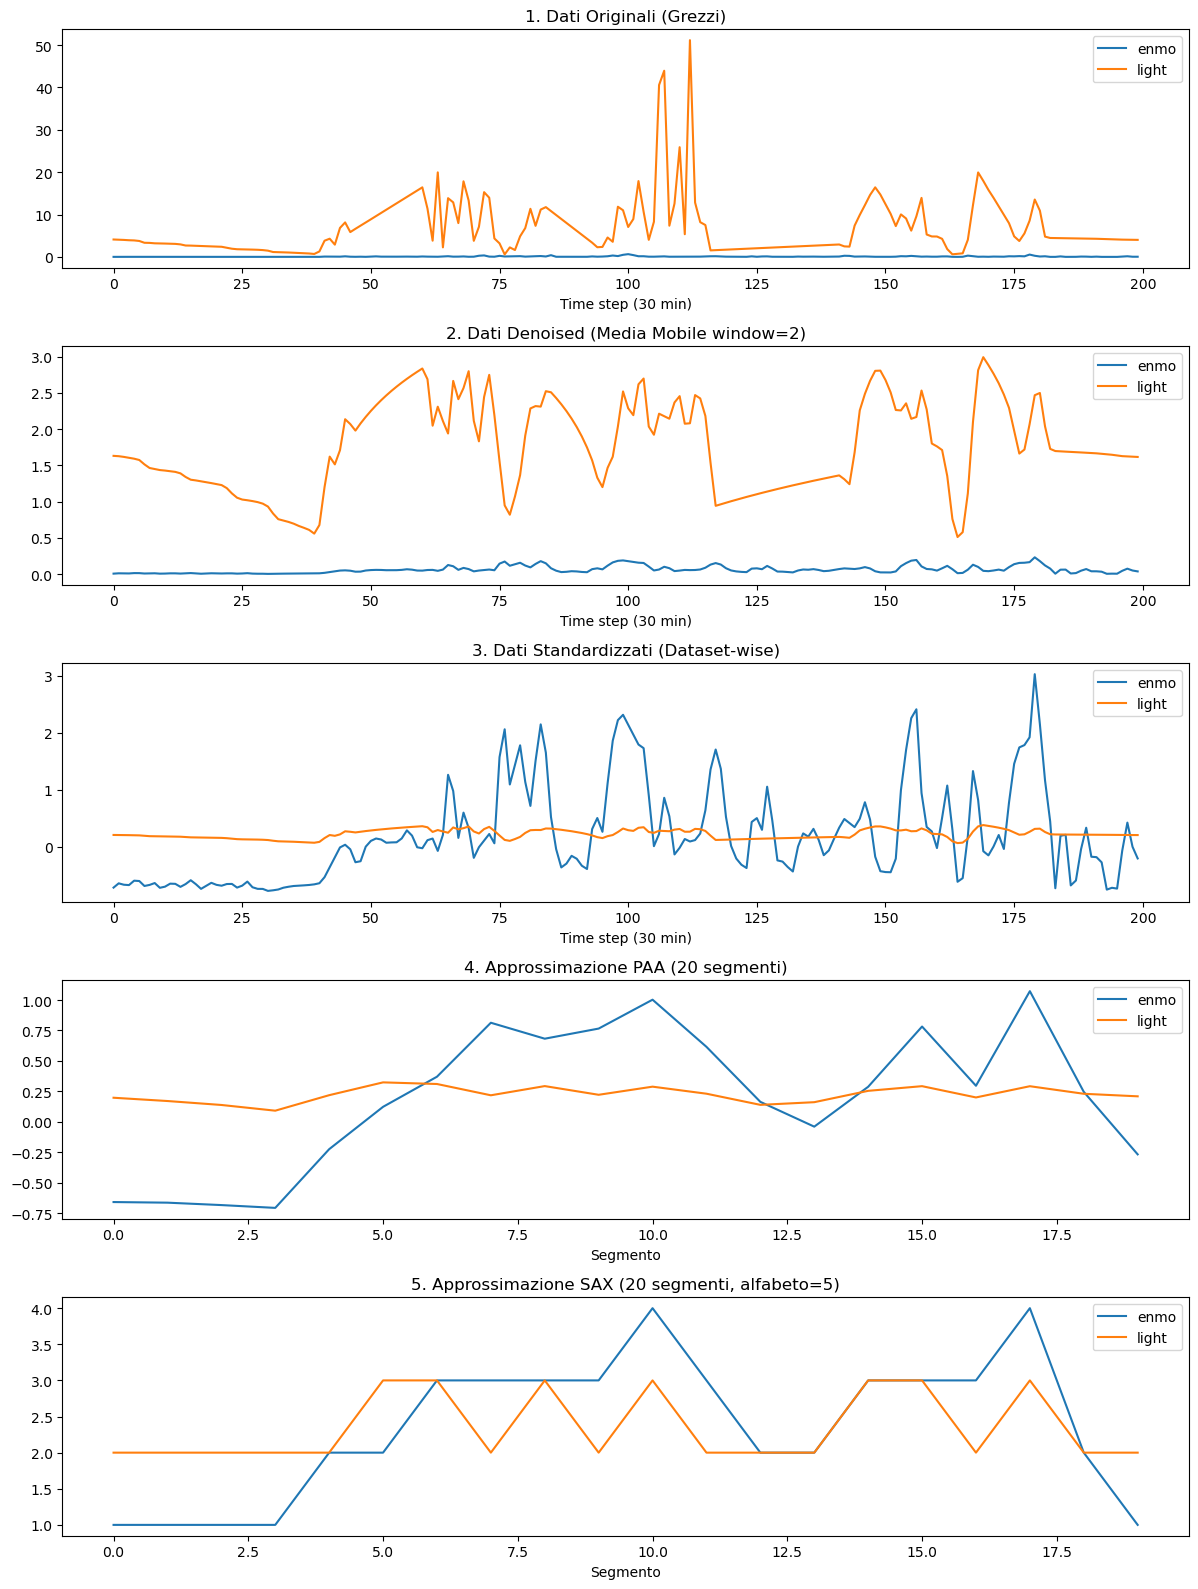

In [20]:
indice = random.randint(0, len(ts) - 1)

print(f"=== TIME SERIES DEL SOGGETTO ALLA POSIZIONE {indice} ===")
fig, axes = plt.subplots(5, 1, figsize=(12, 16), sharex=False)

# 1. Originale
ts[indice][['enmo', 'light']].plot(ax=axes[0], title="1. Dati Originali (Grezzi)")
axes[0].set_xlabel("Time step (30 min)")

# 2. Denoised
ts_denoised[indice][['enmo', 'light']].plot(ax=axes[1], title="2. Dati Denoised (Media Mobile window=2)")
axes[1].set_xlabel("Time step (30 min)")

# 3. Normalizzato
ts_datasetwise_normalized[indice][['enmo', 'light']].plot(ax=axes[2], title="3. Dati Standardizzati (Dataset-wise)")
axes[2].set_xlabel("Time step (30 min)")

# 4. PAA
ts_transformed_paa[indice][['enmo', 'light']].plot(ax=axes[3], title="4. Approssimazione PAA (20 segmenti)")
axes[3].set_xlabel("Segmento")

# 5. SAX
ts_transformed_sax[indice][['enmo', 'light']].plot(ax=axes[4], title="5. Approssimazione SAX (20 segmenti, alfabeto=5)")
axes[4].set_xlabel("Segmento")

plt.tight_layout()
plt.show()